# Bài 2 · CNN phân loại chữ số MNIST

        Ba khối Conv 3×3, ReLU, MaxPool 2×2 và Dropout 0,2. Số kênh 64 → 128 → 256, kích thước ảnh 28 → 14 → 7 → 3. Flatten 2.304 → 512 → 512 → 10 với Dropout 0,2 sau hai tầng ẩn.

        Nguồn gồm slide 02 Keras Examples và notebook Keras gốc. MNIST được tải qua torchvision và chuẩn hóa về [0, 1]. Tập validation tách từ 60.000 ảnh train. Tập test chính thức chỉ dùng sau huấn luyện. Môi trường cần torch, torchvision, torchinfo, numpy và matplotlib.

In [1]:
from pathlib import Path
import os
import sys

project = next((path for path in (Path.cwd(), *Path.cwd().parents)
                if (path / 'src/pytorch_core.py').is_file()), None)
if project is None:
    raise FileNotFoundError('Hãy mở notebook từ thư mục KerasToPytorch hoặc notebooks/')
os.chdir(project)
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

In [2]:
import platform
from time import perf_counter

import matplotlib.pyplot as plt
import torch
from torch import nn
from torchinfo import summary

from src.mnist_experiment import (
    make_loaders, plot_curves, read_rows, save_result, use_glorot_initialization,
)
from src.models.mnist_cnn import MNISTCNN
from src.pytorch_core import evaluate, fit, get_device, seed_everything

seed_everything(42)
device = get_device()
if device.type == 'cpu':
    torch.set_num_threads(int(os.environ.get('MNIST_TORCH_THREADS', min(6, os.cpu_count() or 1))))
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | '
      f'{device} | {torch.get_num_threads()} luồng CPU')
train_loader, val_loader, test_loader = make_loaders(batch_size=128, seed=42)
print(f'Train / validation / test: {len(train_loader.dataset):,} / '
      f'{len(val_loader.dataset):,} / {len(test_loader.dataset):,}')
inputs, labels = next(iter(val_loader))
print('Batch:', tuple(inputs.shape), inputs.dtype, tuple(labels.shape), labels.dtype)

Python 3.13.18 | PyTorch 2.15.0+cpu | cpu | 6 luồng CPU
Train / validation / test: 54,000 / 6,000 / 10,000
Batch: (128, 1, 28, 28) torch.float32 (128,) torch.int64


## Mô hình và số tham số

Khởi tạo Glorot uniform và bias 0. CrossEntropyLoss nhận logits và nhãn nguyên.

In [3]:
model = MNISTCNN().apply(use_glorot_initialization)
model = model.to(device, memory_format=torch.channels_last)
summary(model, input_size=(1, 1, 28, 28), device=device,
        col_names=('input_size', 'output_size', 'num_params'))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
MNISTCNN                                 [1, 1, 28, 28]            [1, 10]                   --
├─Conv2d: 1-1                            [1, 1, 28, 28]            [1, 64, 28, 28]           640
├─ReLU: 1-2                              [1, 64, 28, 28]           [1, 64, 28, 28]           --
├─MaxPool2d: 1-3                         [1, 64, 28, 28]           [1, 64, 14, 14]           --
├─Dropout: 1-4                           [1, 64, 14, 14]           [1, 64, 14, 14]           --
├─Conv2d: 1-5                            [1, 64, 14, 14]           [1, 128, 14, 14]          73,856
├─ReLU: 1-6                              [1, 128, 14, 14]          [1, 128, 14, 14]          --
├─MaxPool2d: 1-7                         [1, 128, 14, 14]          [1, 128, 7, 7]            --
├─Dropout: 1-8                           [1, 128, 7, 7]            [1, 128, 7, 7]            --
├─Conv2d: 1-9                 

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
MNISTCNN                                 [1, 1, 28, 28]            [1, 10]                   --
├─Conv2d: 1-1                            [1, 1, 28, 28]            [1, 64, 28, 28]           640
├─ReLU: 1-2                              [1, 64, 28, 28]           [1, 64, 28, 28]           --
├─MaxPool2d: 1-3                         [1, 64, 28, 28]           [1, 64, 14, 14]           --
├─Dropout: 1-4                           [1, 64, 14, 14]           [1, 64, 14, 14]           --
├─Conv2d: 1-5                            [1, 64, 14, 14]           [1, 128, 14, 14]          73,856
├─ReLU: 1-6                              [1, 128, 14, 14]          [1, 128, 14, 14]          --
├─MaxPool2d: 1-7                         [1, 128, 14, 14]          [1, 128, 7, 7]            --
├─Dropout: 1-8                           [1, 128, 7, 7]            [1, 128, 7, 7]            --
├─Conv2d: 1-9                 

## Huấn luyện 30 epoch

SGD với learning rate 0,01, batch size 128. Thời gian gồm vòng train và validation, đo bằng perf_counter.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
start = perf_counter()
history = fit(model, train_loader, val_loader, criterion, optimizer, device,
              epochs=30, csv_path='logs/history_02_mnist_cnn.csv')
fit_seconds = perf_counter() - start
test = evaluate(model, test_loader, criterion, device)
result = save_result('cnn', model, test, fit_seconds, len(history), device)
print(f"Test loss {result['test_loss']:.4f} | accuracy {result['test_accuracy']:.2%} | "
      f"mốc Keras {result['keras_test_accuracy']:.2%} | "
      f"chênh lệch {result['accuracy_delta_pp']:+.2f} điểm phần trăm")
print(f"Thời gian fit {fit_seconds:.2f} giây | {result['parameters']:,} tham số")

Epoch 01/30 | train 2.2220, accuracy 0.2373 | val 1.7896, accuracy 0.5930 | lr 0.01
Epoch 02/30 | train 1.0153, accuracy 0.6690 | val 0.4626, accuracy 0.8610 | lr 0.01
Epoch 03/30 | train 0.4807, accuracy 0.8452 | val 0.2494, accuracy 0.9285 | lr 0.01
Epoch 04/30 | train 0.3218, accuracy 0.8984 | val 0.1848, accuracy 0.9443 | lr 0.01
Epoch 05/30 | train 0.2533, accuracy 0.9196 | val 0.1492, accuracy 0.9533 | lr 0.01
Epoch 06/30 | train 0.2123, accuracy 0.9340 | val 0.1307, accuracy 0.9590 | lr 0.01
Epoch 07/30 | train 0.1866, accuracy 0.9409 | val 0.1170, accuracy 0.9642 | lr 0.01
Epoch 08/30 | train 0.1671, accuracy 0.9477 | val 0.1056, accuracy 0.9680 | lr 0.01
Epoch 09/30 | train 0.1531, accuracy 0.9520 | val 0.0988, accuracy 0.9687 | lr 0.01
Epoch 10/30 | train 0.1423, accuracy 0.9549 | val 0.0898, accuracy 0.9742 | lr 0.01
Epoch 11/30 | train 0.1351, accuracy 0.9573 | val 0.0852, accuracy 0.9750 | lr 0.01
Epoch 12/30 | train 0.1259, accuracy 0.9599 | val 0.0819, accuracy 0.9740 | 

## So sánh với MLP

        Kết quả MLP đọc từ notebook 01 đã chạy. Hai mô hình dùng chung seed, tập dữ liệu và thiết bị trong lần đo lưu sẵn. Tổng thời gian gồm số epoch riêng của mỗi mô hình.

MLP: 95.17% test, 669,706 tham số, 37.52 giây / 20 epoch
CNN: 98.82% test, 1,817,610 tham số, 2112.32 giây / 30 epoch


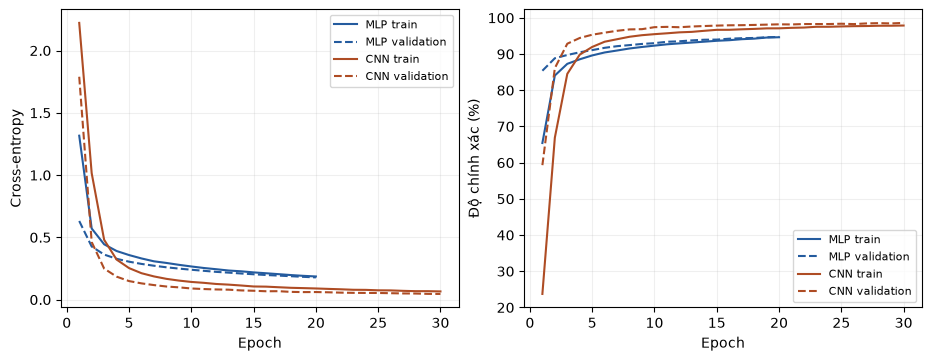

In [5]:
mlp_history = Path('logs/history_01_mnist_mlp.csv')
mlp_result = Path('logs/result_01_mnist_mlp.csv')
series = {'CNN': history}
if mlp_history.is_file() and mlp_result.is_file():
    series = {'MLP': read_rows(mlp_history), 'CNN': history}
    baseline = read_rows(mlp_result)[0]
    for row in (baseline, result):
        print(f"{row['model']}: {float(row['test_accuracy']):.2%} test, "
              f"{int(row['parameters']):,} tham số, "
              f"{float(row['fit_seconds']):.2f} giây / {row['epochs']} epoch")
    plot_curves(series, 'figures/02_mnist_cnn_vs_mlp.png')
else:
    print('Chạy notebook 01 để có log so sánh MLP và CNN.')
    plot_curves(series, 'figures/02_mnist_cnn_curves.png')
plt.show()

## Dự đoán một ảnh test

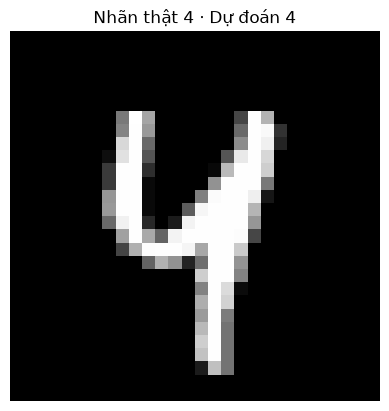

In [6]:
sample, actual = test_loader.dataset[42]
with torch.inference_mode():
    probabilities = model(sample.unsqueeze(0).to(device)).softmax(dim=1)
predicted = probabilities.argmax(dim=1).item()
plt.imshow(sample.squeeze(0), cmap='gray')
plt.title(f'Nhãn thật {actual.item()} · Dự đoán {predicted}')
plt.axis('off')
plt.show()

## Thử nghiệm bổ sung · Adam trong 10 epoch

Cấu hình này giữ kiến trúc, dữ liệu và cách tách tập như CNN dùng SGD. Adam với learning rate 0,001 thay đổi cách cập nhật trọng số và chạy 10 epoch. Kết quả lưu riêng với hậu tố _adam. Bảng so sánh phía trên dùng CNN chạy SGD đủ 30 epoch như slide.

In [7]:
seed_everything(42)
adam_train, adam_val, adam_test = make_loaders(batch_size=128, seed=42)
adam_model = MNISTCNN().apply(use_glorot_initialization)
adam_model = adam_model.to(device, memory_format=torch.channels_last)
adam_optimizer = torch.optim.Adam(adam_model.parameters(), lr=0.001)
adam_start = perf_counter()
adam_history = fit(
    adam_model, adam_train, adam_val, criterion, adam_optimizer, device,
    epochs=10, csv_path='logs/history_02_mnist_cnn_adam.csv',
)
adam_seconds = perf_counter() - adam_start
adam_test_scores = evaluate(adam_model, adam_test, criterion, device)
adam_result = save_result(
    'cnn', adam_model, adam_test_scores, adam_seconds, len(adam_history), device,
    variant='adam',
)
print(f"Validation {adam_history[-1]['val_accuracy']:.2%} | "
      f"test {adam_result['test_accuracy']:.2%} | "
      f"chênh lệch mốc Keras {adam_result['accuracy_delta_pp']:+.2f} điểm phần trăm")

Epoch 01/10 | train 0.2246, accuracy 0.9251 | val 0.0573, accuracy 0.9820 | lr 0.001
Epoch 02/10 | train 0.0582, accuracy 0.9820 | val 0.0550, accuracy 0.9842 | lr 0.001
Epoch 03/10 | train 0.0413, accuracy 0.9878 | val 0.0342, accuracy 0.9902 | lr 0.001
Epoch 04/10 | train 0.0336, accuracy 0.9902 | val 0.0352, accuracy 0.9902 | lr 0.001
Epoch 05/10 | train 0.0303, accuracy 0.9905 | val 0.0314, accuracy 0.9907 | lr 0.001
Epoch 06/10 | train 0.0279, accuracy 0.9913 | val 0.0281, accuracy 0.9913 | lr 0.001
Epoch 07/10 | train 0.0237, accuracy 0.9929 | val 0.0276, accuracy 0.9927 | lr 0.001
Epoch 08/10 | train 0.0205, accuracy 0.9937 | val 0.0392, accuracy 0.9905 | lr 0.001
Epoch 09/10 | train 0.0194, accuracy 0.9941 | val 0.0370, accuracy 0.9908 | lr 0.001
Epoch 10/10 | train 0.0210, accuracy 0.9938 | val 0.0277, accuracy 0.9930 | lr 0.001
Validation 99.30% | test 99.35% | chênh lệch mốc Keras +0.46 điểm phần trăm
